<a href="https://colab.research.google.com/github/minxuan0923/AML_Assignment/blob/anne/Set1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import libraries

In [7]:
import pandas as pd
from scipy.io import arff
import requests
from io import StringIO
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, optimizers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt


# Load Dataset

In [8]:
URL = (
    "https://raw.githubusercontent.com/"
    "minxuan0923/AML_Assignment/main/data/"
    "UCI_Phishing_Training_Dataset.arff"
)

response = requests.get(URL, timeout=30)
response.raise_for_status()

data, meta = arff.loadarff(StringIO(response.text))

df = pd.DataFrame(data)

for col in df.select_dtypes([object]):
    df[col] = pd.to_numeric(df[col].str.decode('utf-8'))

x_data = df.drop(columns =['Result'])
y_data = df['Result']

# Spliting

In [9]:
X_train, X_test, y_train, y_test = train_test_split(x_data, y_data, random_state = 42, test_size=0.2, stratify=y_data)

# Encoding

In [10]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)

# One-hot-encoding X values
X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

# Convert y values - phishing to "1" and legitimate to "0"
y_train = y_train.replace({-1: 1, 1: 0})
y_test = y_test.replace({-1: 1, 1: 0})

# Evaluation Helper

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

In [17]:
results = {}

def evaluate(name, y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "FN": fn, "FP": fp,
        "FNR": fn / (fn + tp),
    }
    print(pd.Series(results[name]).round(4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=['Legitimate', 'Phishing']).plot(cmap='Blues')
    plt.title(f"Confusion Matrix: {name}"); plt.show()

# Set 1
Logistic Regression with original features

In [15]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression

Best C: {'C': 10}
Best CV recall: 0.9232
Accuracy      0.9389
Precision     0.9415
Recall        0.9194
F1            0.9303
ROC-AUC       0.9886
FN           79.0000
FP           56.0000
FNR           0.0806
dtype: float64


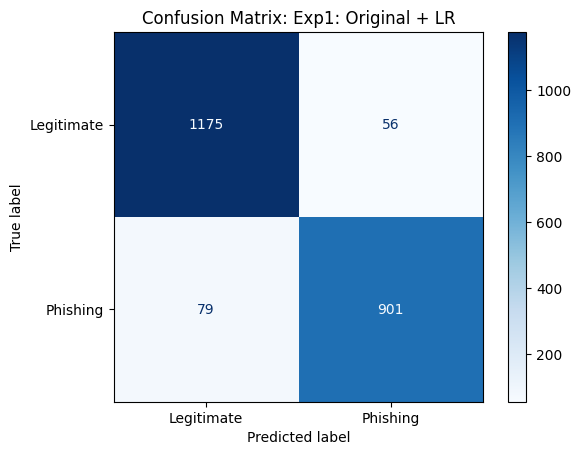

,param_C,mean_test_score,std_test_score
0,0.01,0.903008,0.006251
1,0.10,0.918325,0.005997
2,1.00,0.921898,0.006589
3,10.00,0.923174,0.006930
4,100.00,0.922918,0.007172


In [18]:
# 5-fold stratified cross-validation, run on the training set only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Declare the grid search
grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=2000, solver='liblinear'),
    param_grid={'C': [0.01, 0.1, 1, 10, 100]},   # candidate regularization strengths
    scoring='recall',                             # optimise for catching phishing sites
    cv=cv
)

# Fit it (this trains 5 models for each value of C and picks the best)
grid.fit(X_train_encoded, y_train)

print("Best C:", grid.best_params_)
print("Best CV recall:", round(grid.best_score_, 4))

# Best model, already refit on the full training set
lr = grid.best_estimator_

lr_pred = lr.predict(X_test_encoded)
lr_prob = lr.predict_proba(X_test_encoded)[:, 1]
evaluate("Exp1: Original + LR", y_test, lr_pred, lr_prob)

pd.DataFrame(grid.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']]